# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u

from gammapy.data import DataStore

In [14]:
import os
os.environ["GAMMAPY_DATA"] = "/Users/tbylund/DATA/GAMMAPY_DATA/"

# Using a datastore

A `gammapy.data.DataStore` is a Gammapy object used to retrieve sets of observations from a larger collection. It has some functions to help selecting subsets of all the available observations

## Create a `DataStore` from a prepared diretory

Sometimes data is provided in one big directory along with an index table, in this case a datastore can be creates easily with `from_dir`:

In [3]:
data_store = DataStore.from_dir("$GAMMAPY_DATA/hess-dl3-dr1")

data_store.info()

Data store:
HDU index table:
BASE_DIR: /Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1
Rows: 630
OBS_ID: 20136 -- 47829
HDU_TYPE: [np.str_('aeff'), np.str_('bkg'), np.str_('edisp'), np.str_('events'), np.str_('gti'), np.str_('psf')]
HDU_CLASS: [np.str_('aeff_2d'), np.str_('bkg_3d'), np.str_('edisp_2d'), np.str_('events'), np.str_('gti'), np.str_('psf_table')]


Observation table:
Observatory name: 'N/A'
Number of observations: 105



A `DataStore` contains two tables. The main one is the HDU table which connects EVENTS files with its matching IRF files.

In [4]:
data_store.hdu_table[:10]

OBS_ID,HDU_TYPE,HDU_CLASS,FILE_DIR,FILE_NAME,HDU_NAME,SIZE
int64,bytes6,bytes9,bytes4,bytes34,bytes6,int64
20136,aeff,aeff_2d,data,hess_dl3_dr1_obs_id_020136.fits.gz,aeff,11520
20136,bkg,bkg_3d,data,hess_dl3_dr1_obs_id_020136.fits.gz,bkg,207360
20136,edisp,edisp_2d,data,hess_dl3_dr1_obs_id_020136.fits.gz,edisp,377280
20136,events,events,data,hess_dl3_dr1_obs_id_020136.fits.gz,events,414720
20136,gti,gti,data,hess_dl3_dr1_obs_id_020136.fits.gz,gti,5760
20136,psf,psf_table,data,hess_dl3_dr1_obs_id_020136.fits.gz,psf,118080
20137,aeff,aeff_2d,data,hess_dl3_dr1_obs_id_020137.fits.gz,aeff,11520
20137,bkg,bkg_3d,data,hess_dl3_dr1_obs_id_020137.fits.gz,bkg,207360
20137,edisp,edisp_2d,data,hess_dl3_dr1_obs_id_020137.fits.gz,edisp,377280


The other table is optional and is the observation summary. It provides informations (metadata) on the observations present in the `DataStore`. Here you can find things like the zenith angle, the run duration, and the observation date. 

In [5]:
data_store.obs_table[:2]

OBS_ID,RA_PNT,DEC_PNT,GLON_PNT,GLAT_PNT,ZEN_PNT,ALT_PNT,AZ_PNT,OBJECT,RA_OBJ,DEC_OBJ,OFFSET_OBJ,ONTIME,LIVETIME,DEADC,TSTART,TSTOP,DATE-OBS,TIME-OBS,DATE-END,TIME-END,N_TELS,TELLIST,QUALITY,MUONEFF,EVENT_COUNT,TARGET_NAME,TARGET_TAG,TARGET_OFFSET,SAFE_ENERGY_LO,SAFE_ENERGY_HI
,deg,deg,deg,deg,deg,deg,deg,,deg,deg,deg,s,s,,s,s,,,,,,,,,,,,deg,TeV,TeV
int64,float32,float32,float32,float32,float32,float32,float32,bytes18,float32,float32,float32,float32,float32,float32,float64,float64,bytes10,bytes12,bytes10,bytes12,int64,bytes7,int64,float32,int64,bytes21,bytes14,float32,float32,float32
20136,228.6125,-58.771667,320.56754,-0.8857012,38.512962,51.487038,195.73102,MSH15-52,228.6125,-59.271667,0.5,1682.0,1521.0269,0.9042966,101962602.0,101964284.0,2004-03-26,02:57:46.184,2004-03-26,03:25:48.184,4,"1,2,3,4",0,1.2132596,11243,MSH 15-52,msh1552,0.38821736,0.40738028,100.0
20137,228.6125,-59.771667,320.04724,-1.7397733,40.21616,49.78384,199.6482,MSH15-52,228.6125,-59.271667,0.5,902.0,819.2054,0.90821,101964441.0,101965343.0,2004-03-26,03:28:25.184,2004-03-26,03:43:27.184,4,"1,2,3,4",0,1.2139559,5693,MSH 15-52,msh1552,0.6156251,0.40738028,100.0


The obs table offers some convenience functions to perform observation selection.

The most useful one allows you to select observationd around a given direction.

In [6]:
position = SkyCoord(ra=83.63, dec=22.01, unit="deg", frame="icrs")
filtered_obs_table = data_store.obs_table.select_sky_circle(position, 3*u.deg)

print(filtered_obs_table)

OBS_ID   RA_PNT   DEC_PNT  ... TARGET_OFFSET SAFE_ENERGY_LO SAFE_ENERGY_HI
          deg       deg    ...      deg           TeV            TeV      
------ --------- --------- ... ------------- -------------- --------------
 23523  83.63333 21.514444 ...      0.500049      0.8709636          100.0
 23526  83.63333 22.514444 ...    0.49995112     0.70794576          100.0
 23559 85.253334 22.014444 ...     1.5021166     0.66069347          100.0
 23592 82.013336 22.014444 ...     1.5016365      0.8709636          100.0


Now you can extract the identifiers (ObsID) of the selected observations.

In [7]:
filtered_obs_table['OBS_ID'].data

array([23523, 23526, 23559, 23592], dtype='>i8')

**Exercice :** Compute the total observation time of observations taken at less than 2° from the SNR RX J1713-3946 position in the HESS DL3 DR1.

In [8]:
from astropy.time import Time

target = SkyCoord.from_name("RX J1713.7-3946")

filtered = data_store.obs_table.select_sky_circle(target, 2.*u.deg)
total = np.sum(filtered["ONTIME"].quantity)

print(f"The total observation time is { total.to('h') }")

The total observation time is 7.010833740234375 h


## Create a DataStore from a set of files

Sometimes data is provided only as a set of files, in this case you can use `from_events_files` to create the datastore. You need to provide an explicit list of files, here we use the `glob` method of the `Path` object to find all the files in the data directory of the H.E.S.S. public data release and save that as a list

In [28]:
from pathlib import Path
files =  list(Path("/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data/").glob("*fits.gz"))

In [30]:
ds_from_files = DataStore.from_events_files(events_paths=files)

In [31]:
ds_from_files.hdu_table[:10]

HDU_TYPE,HDU_CLASS,HDU_NAME,OBS_ID,FILE_DIR,FILE_NAME
str6,str10,str21,int64,str50,str34
events,events,EVENTS,33798,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033798.fits.gz
gti,gti,GTI,33798,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033798.fits.gz
aeff,aeff_2d,EFFECTIVE AREA,33798,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033798.fits.gz
edisp,edisp_2d,ENERGY DISPERSION,33798,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033798.fits.gz
psf,psf_3gauss,POINT SPREAD FUNCTION,33798,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033798.fits.gz
bkg,bkg_3d,BACKGROUND,33798,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033798.fits.gz
events,events,EVENTS,33788,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033788.fits.gz
gti,gti,GTI,33788,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033788.fits.gz
aeff,aeff_2d,EFFECTIVE AREA,33788,/Users/tbylund/DATA/GAMMAPY_DATA/hess-dl3-dr1/data,hess_dl3_dr1_obs_id_033788.fits.gz


## Extracting observations from a DataStore

`Observations` is a sequence (i.e. a list) of `Observation` objects.

In [32]:
observations = data_store.get_observations(filtered_obs_table['OBS_ID'])

In [33]:
print(observations)

Observations
Number of observations: 4
Observation

	obs id            : 23523 
 	tstart            : 53343.92
	tstop             : 53343.94
	duration          : 1687.00 s
	pointing (icrs)   : 83.6 deg, 21.5 deg

	deadtime fraction : 6.2%
Observation

	obs id            : 23526 
 	tstart            : 53343.95
	tstop             : 53343.97
	duration          : 1683.00 s
	pointing (icrs)   : 83.6 deg, 22.5 deg

	deadtime fraction : 6.6%
Observation

	obs id            : 23559 
 	tstart            : 53345.96
	tstop             : 53345.98
	duration          : 1686.00 s
	pointing (icrs)   : 85.3 deg, 22.0 deg

	deadtime fraction : 6.4%
Observation

	obs id            : 23592 
 	tstart            : 53347.91
	tstop             : 53347.93
	duration          : 1686.00 s
	pointing (icrs)   : 82.0 deg, 22.0 deg

	deadtime fraction : 6.2%



One can access observations by their index in the list, or simply loop over all observations.

`Observation` contains metadata on the observation.

In [34]:
obs = observations[1]
print(obs.meta.obs_info)

obs_id=23526 telescope='HESS' instrument='H.E.S.S. Phase I' sub_array=None observation_mode='WOBBLE'


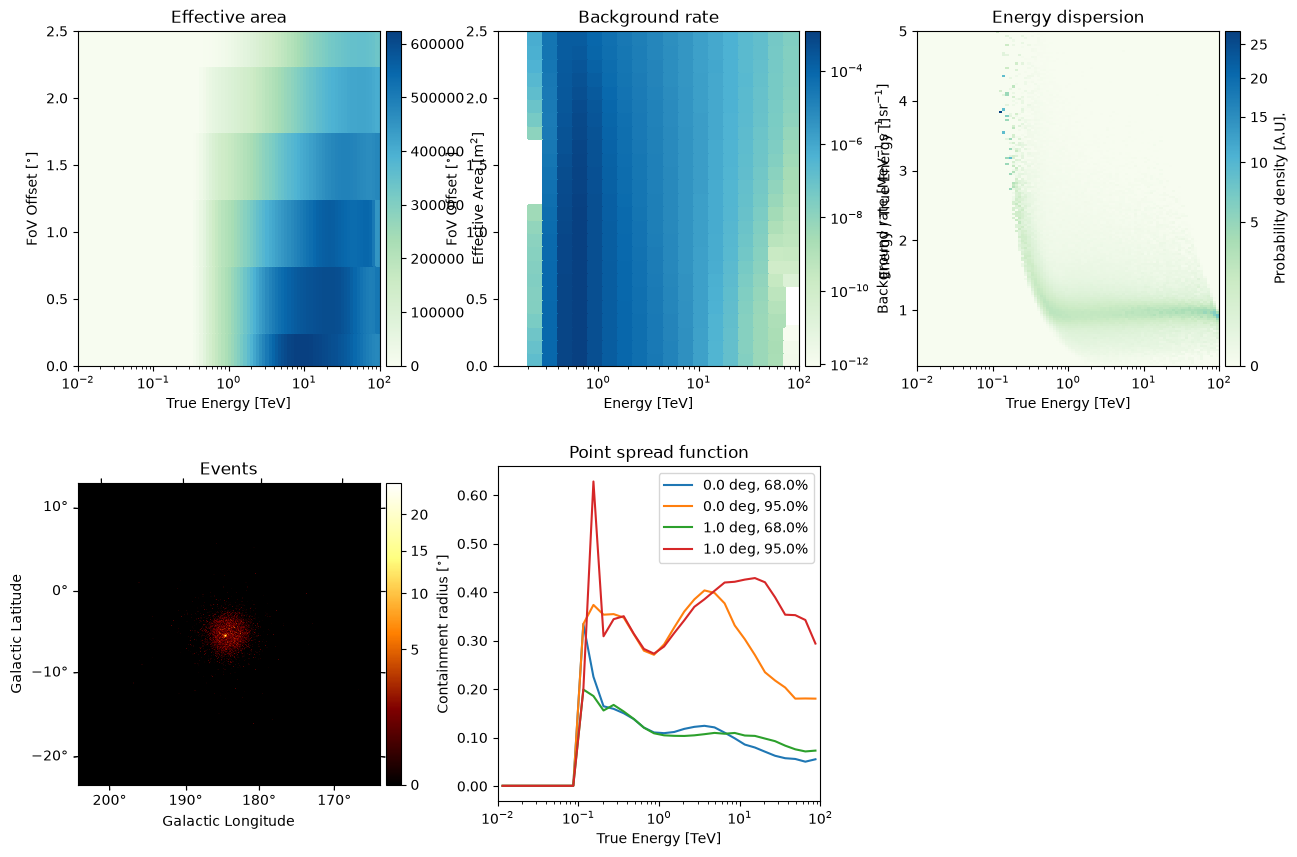

In [35]:
obs.peek()

# An Observation

Each observation contains a list of events, some IRFs, and some information about the observation as a whole, for example the observatory and observation mode

In [36]:
print(obs.meta.obs_info)

obs_id=23526 telescope='HESS' instrument='H.E.S.S. Phase I' sub_array=None observation_mode='WOBBLE'


When the observation was taken

In [37]:
print(obs.meta.time_info)

time_start=<Time object: scale='tt' format='mjd' value=53343.95421509259> time_stop=<Time object: scale='tt' format='mjd' value=53343.97369425926> reference_time=<Time object: scale='tt' format='mjd' value=51910.00074287037>


What the target was 

In [38]:
print(obs.meta.target)

name='Crab Nebula' position=<SkyCoord (ICRS): (ra, dec) in deg
    (83.63333333, 22.01444444)>


And with a bit of math, what the average zenith angle was

In [39]:
print(90*u.deg - obs.meta.pointing.altaz_mean.alt)

45d46m45.44677793s


## Events

Gamma-ray like events (i.e. at DL3) are stored in an `EventList` which contains an `astropy.table.Table`

In [40]:
print(obs.events)

EventList
---------

  Instrument       : H.E.S.S. Phase I
  Telescope        : HESS
  Obs. ID          : 23526

  Number of events : 7581
  Event rate       : 4.504 1 / s

  Time start       : 53343.95421509259
  Time stop        : 53343.97369425926

  Min. energy      : 2.88e-01 TeV
  Max. energy      : 8.49e+01 TeV
  Median energy    : 8.36e-01 TeV

  Max. offset      : 19.8 deg



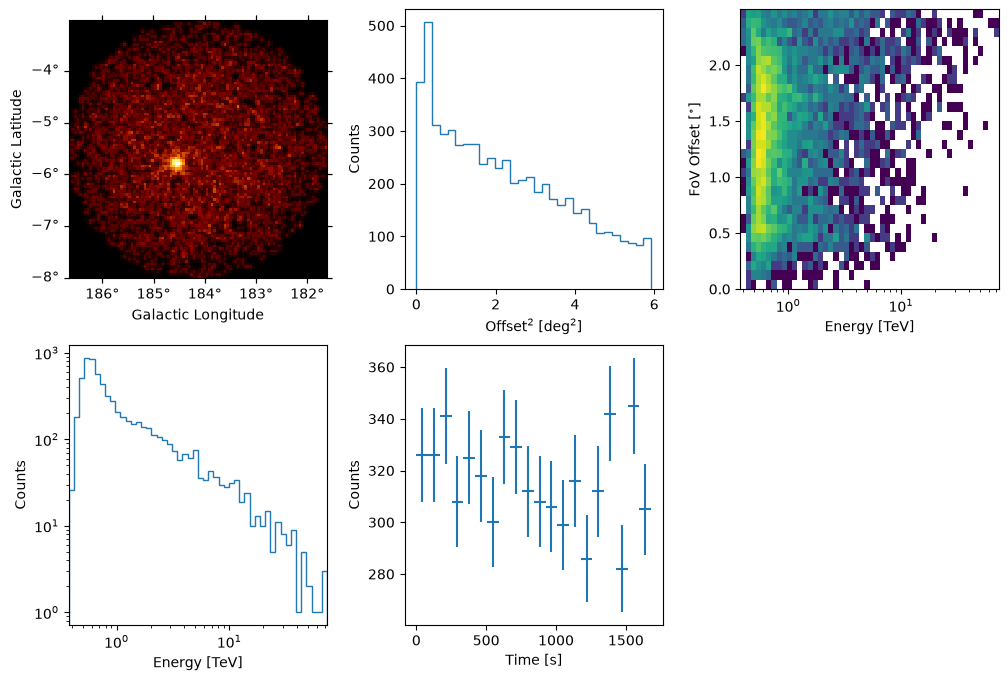

In [41]:
obs.events.select_offset([0,2.5]*u.deg).peek()

**Exercice**: how many events are there in ObsID 23523 within a circular ON region of 0.2 deg from the Crab?

*Hint : Look for a region selection tool in the API documentation of EventList.*

In [42]:
from regions import CircleSkyRegion
region = CircleSkyRegion(center=position, radius=0.2*u.deg)
events_ON = obs.events.select_region(region)

N_ON = len(events_ON.table)
print(f"Number of ON events = {N_ON}")

Number of ON events = 350


**Advanced exercice**: measure OFF counts in a symetrical region w.r.t. pointing direction. Compute the excess counts in the ON and the associated Li and Ma significance.

*Hints: Compute the offset and position angle of the ON region w.r.t. `EventList.pointing_radec` and use `SkyCoord.directional_offset_by` to find the OFF region.
Then use CountsStatistics as in https://docs.gammapy.org/2.1/user-guide/stats/index.html#wstat-counts-statistic*

In [43]:
# Find the pointing direction, calculate its offset 
pnt_icrs = obs.pointing.get_icrs(obstime=obs.tmid)
separation = pnt_icrs.separation(position)
position_angle = pnt_icrs.position_angle(position).to("deg")
print(position_angle)

# Offset from that angle by 180
wobble_position = pnt_icrs.directional_offset_by(position_angle=180*u.deg-position_angle, separation=separation)
print(wobble_position)

# Use as center for a CircleSkyRegion
wobble_region = CircleSkyRegion(center=wobble_position, radius=0.2*u.deg)
events_OFF = obs.events.select_region(wobble_region)

N_OFF = len(events_OFF.table)
print(f"Number of OFF events = {N_OFF}")

180d21m03.64757954s
<SkyCoord (ICRS): (ra, dec) in deg
    (83.62997558, 23.01888882)>
Number of OFF events = 52


In [47]:
# Calculate WStat
from gammapy.stats import WStatCountsStatistic
alpha = 1
stat = WStatCountsStatistic(N_ON, N_OFF, alpha)

print(stat)

WStatCountsStatistic
  Total counts                    : 350.00 
  Total background counts         : 52.00
  Total excess counts             : 298.00
  Total significance              : 15.74
  p - value                       : 0.000
  Total number of bins            : 1
  Off counts                      : 52.00 
  alpha                           : 1.00 
  Predicted signal counts         : 0.00 



## Instrument response functions

Let's now look at the IRFs stored in the observation object. Typically we separate the total *instrument response* into three parts: Effective Area, Energy Dispersion, Point Spread Function. Additionally the data producer has also created and attached a background model. 

### Effective area

The effective area IRF is a set of tabulated values at given coordinates in true 3D space 

In [44]:
print(obs.aeff)

EffectiveAreaTable2D
--------------------

  axes  : ['energy_true', 'offset']
  shape : (96, 6)
  ndim  : 2
  unit  : m2
  dtype : >f4



Let's have a view on the IRF.

/Users/tbylund/miniforge3/envs/gammapy-2p1/lib/python3.13/site-packages/astropy/units/quantity.py:676: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


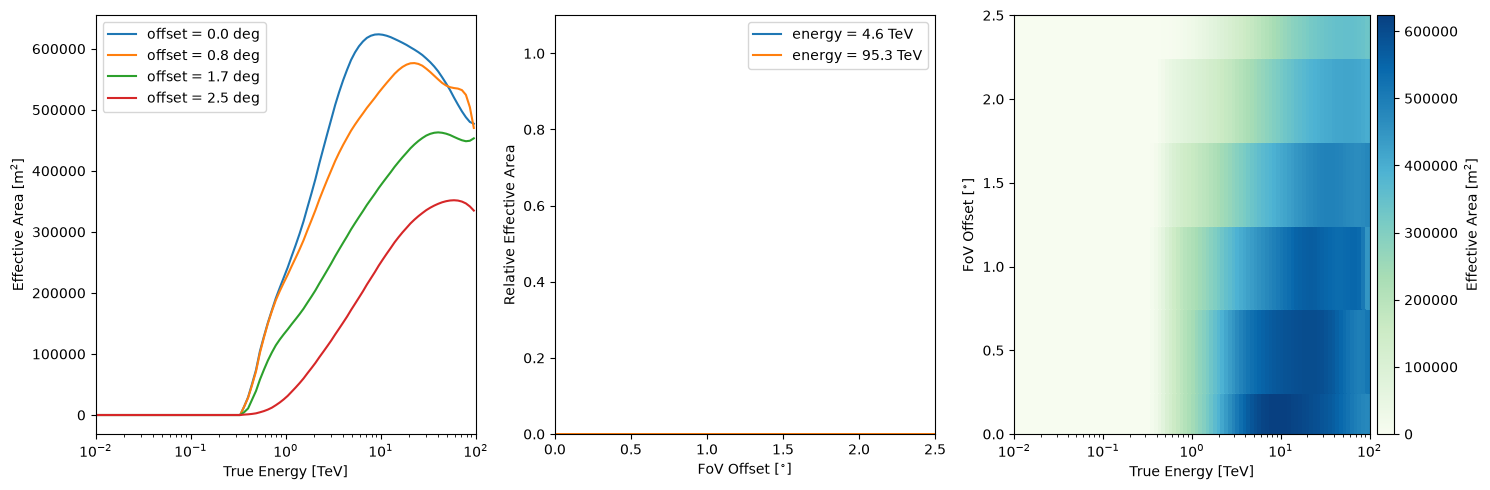

In [45]:
obs.aeff.peek()

The IRF also behaves like a function (it interpolates over the tabulated values).

In [46]:
obs.aeff.evaluate(energy_true=10*u.TeV, offset=1.2*u.deg)

<Quantity 467682.84572009 m2>

**Exercice**: plot the effective area offset dependence at 500 GeV, 1 and 10 TeV.

*Hint: look for the existing plot functions in the API.*

<Axes: xlabel='FoV Offset [$\\mathrm{{}^{\\circ}}$]', ylabel='Relative Effective Area'>

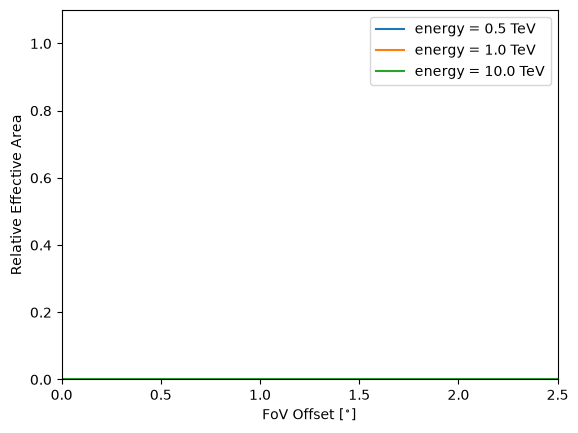

In [48]:
obs.aeff.plot_offset_dependence(energy=[0.5, 1., 10]*u.TeV)

**Advanced exercice**: Re-implement the plotting yourself.

/var/folders/dg/_hmh5c8n3h9b5zht0p884cgw0000gp/T/ipykernel_3636/650298372.py:7: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.semilogy(offsets, aeffs, label=energy)
/var/folders/dg/_hmh5c8n3h9b5zht0p884cgw0000gp/T/ipykernel_3636/650298372.py:7: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.semilogy(offsets, aeffs, label=energy)


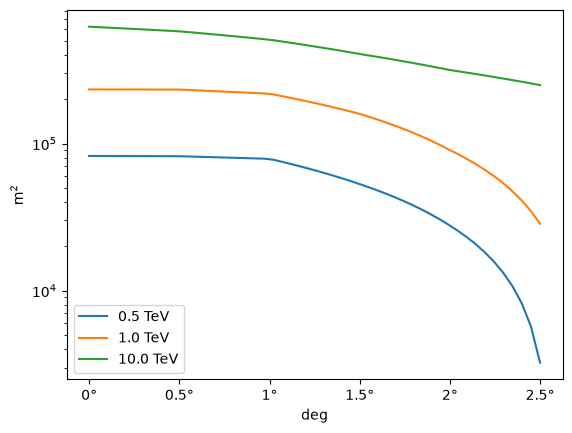

In [49]:
from astropy.visualization import quantity_support
offsets = np.linspace(0,2.5)*u.deg

for energy in [0.5, 1.0, 10.]*u.TeV:
    aeffs = obs.aeff.evaluate(energy_true=energy, offset=offsets)
    with quantity_support():
        plt.semilogy(offsets, aeffs, label=energy)
plt.legend()

#### Evolution of the observation threshold during an observation night

Because a target is moving in the sky, its zenith angle will vary during the night. Because the energy threshold of a Cherenkov increase with the zenith angle, the latter will vary during the night.  

GADF effective area can contain an effective low energy threshold for the observation. On the HESS DL3 DR1 you can access it with:

In [50]:
obs.aeff.meta['LO_THRES']

0.707945784384138

**Exercice** : Extract observations of PKS 2155-304 taken on the night of July 29th to 30th 2006 in the HESS DL3 DR1 datastore. How does the observation threshold evolve as a function of observation time during the night? 

How does it compare to the zenith angle of the target as a function of time?

*Hint: IRCS coordinate is (329.717, -30.226). Use astropy.time.Time. Also note that `Observation.tmid` is a shortcut to the mid observation time of the `Observation`.*
*See also [astropy's doc on altitude of celestial objects](https://docs.astropy.org/en/latest/generated/examples/coordinates/plot_obs-planning.html#determining-and-plotting-the-altitude-azimuth-of-a-celestial-object)*

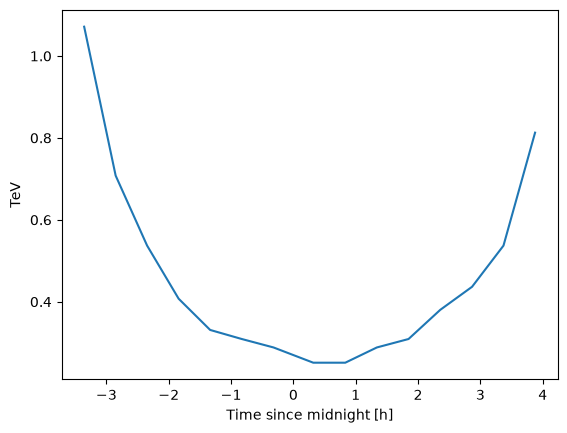

In [51]:
from astropy.time import Time

target = SkyCoord(329.717, -30.226, unit="deg", frame="icrs")
tstart = Time("2006-07-29T16:00")
tstop = Time("2006-07-30T10:00")

filtered = data_store.obs_table.select_sky_circle(target, 2.5*u.deg)
filtered = filtered.select_time_range([tstart, tstop])

pks_observations = data_store.get_observations(filtered["OBS_ID"])

thresholds = [obs.aeff.meta['LO_THRES'] for obs in pks_observations]*u.TeV    
times = Time([obs.tmid for obs in pks_observations])

# This is the time in the 
delta_times = times - Time("2006-07-30T00:00")
with quantity_support():
    plt.plot(delta_times.to("h"), thresholds)
    plt.xlabel("Time since midnight [h]")

### Energy dispersion

Provides the energy resolution as a function of position and true energy. It gives the probability to measure a given energy for a given true energy. It is stored as a function of migra = energy/energy_true

In [52]:
print(obs.edisp)

EnergyDispersion2D
------------------

  axes  : ['energy_true', 'migra', 'offset']
  shape : (96, 160, 6)
  ndim  : 3
  unit  : 
  dtype : >f4



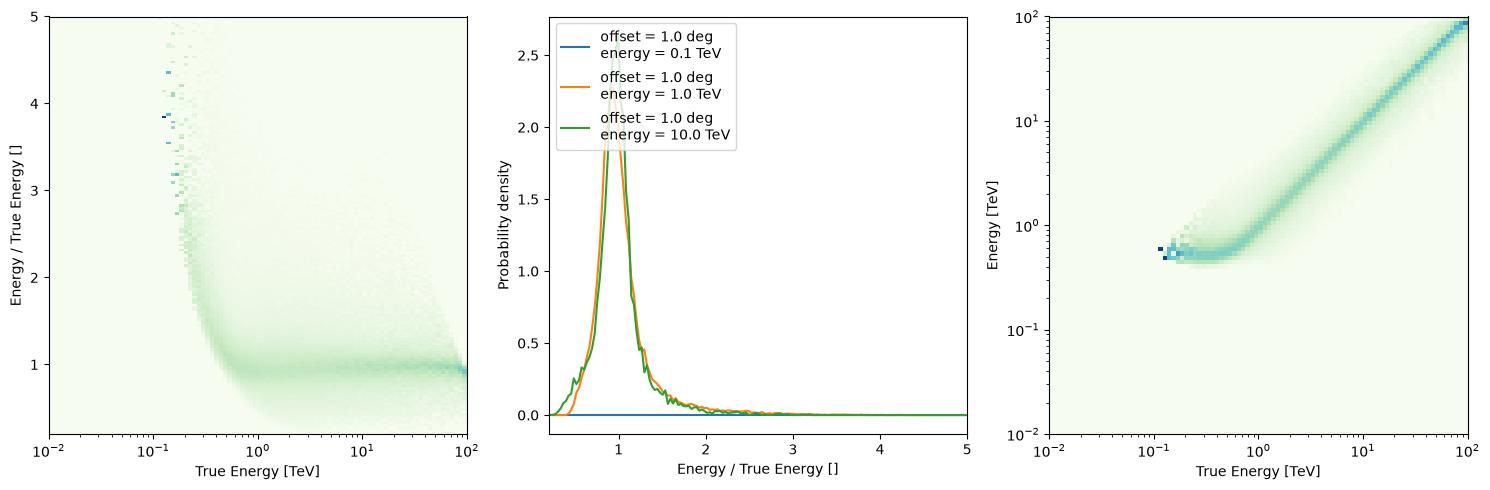

In [53]:
obs.edisp.peek()

For a given set of measurement, we use the `EDispKernel` with gives probability to measure a given energy for a given true energy.

In [54]:
kernel = obs.edisp.to_edisp_kernel(offset=0.5*u.deg)

<Axes: xlabel='True Energy [$\\mathrm{TeV}$]', ylabel='Energy [$\\mathrm{TeV}$]'>

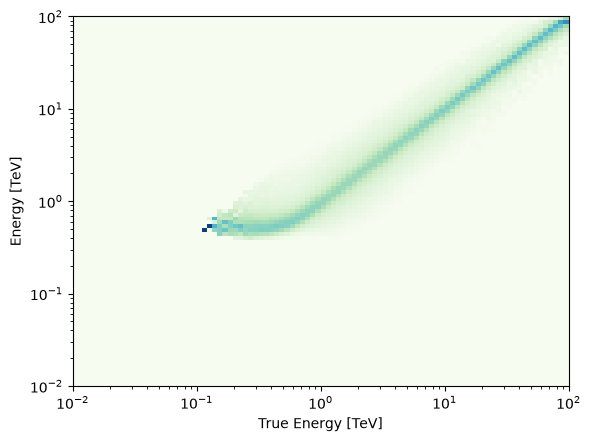

In [55]:
kernel.plot_matrix()

### Point spread function

The PSF gives the probability to observe a photon as given distance from its true direction (the `rad` quantity) as a function of true energy and sourc eposition in the FoV.

In [56]:
print(obs.psf)

PSF3D
-----

  axes  : ['energy_true', 'offset', 'rad']
  shape : (32, 6, 144)
  ndim  : 3
  unit  : 1 / sr
  dtype : >f4



One can compute containment radius as a measurement of the breadth of the PSF

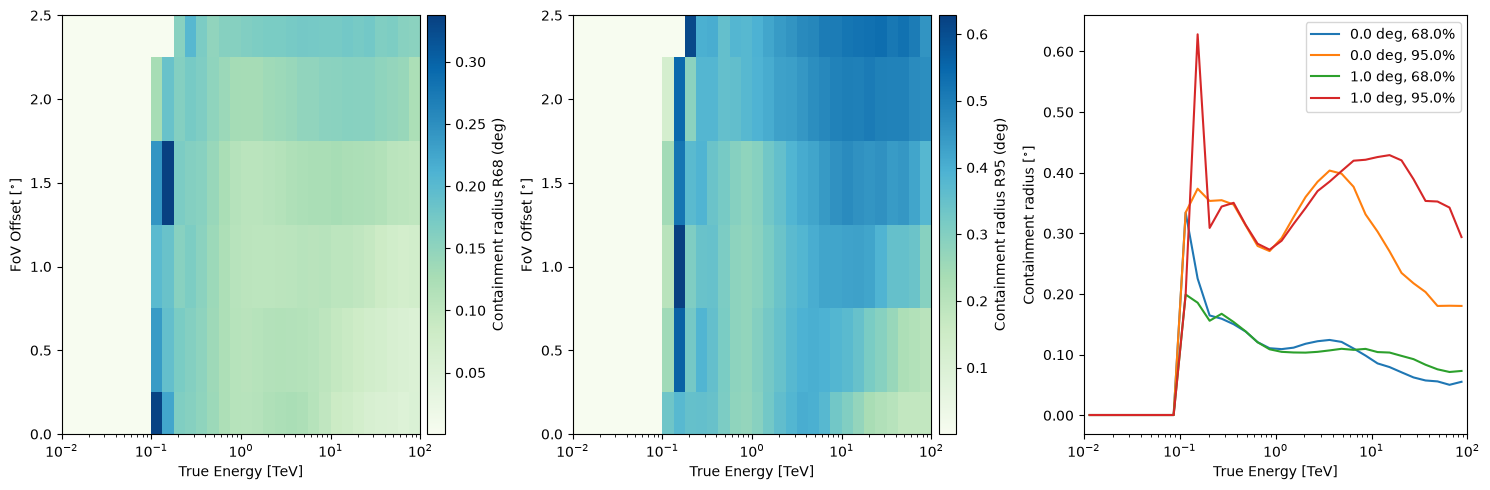

In [57]:
obs.psf.peek()

PSF is a probability. The PSF radius typically decreases with energy.

<Axes: xlabel='Source Offset [$\\mathrm{{}^{\\circ}}$]', ylabel='PSF [$\\mathrm{sr^{-1}}$]'>

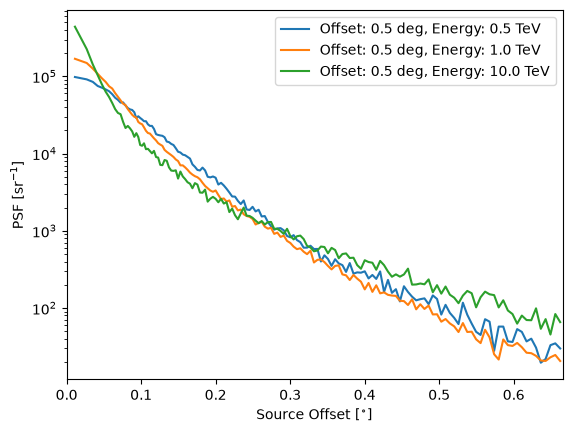

In [58]:
obs.psf.plot_psf_vs_rad(offset=[0.5]*u.deg, energy_true=[0.5, 1, 10]*u.TeV)

### Background

In [59]:
print(obs.bkg)

Background3D
------------

  axes  : ['energy', 'fov_lon', 'fov_lat']
  shape : (20, 50, 50)
  ndim  : 3
  unit  : 1 / (MeV s sr)
  dtype : >f4



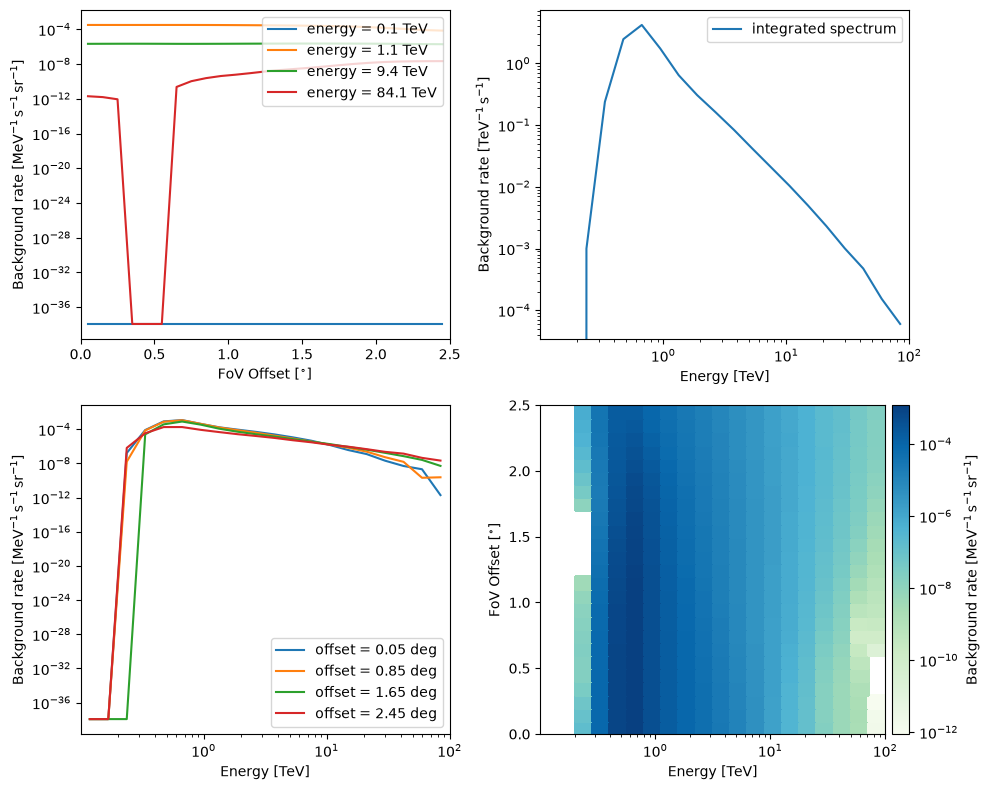

In [60]:
obs.bkg.peek()

# External IRFs

You can also load IRFs without the full `DataStore` with `load_irf_dict_from_file`

In [61]:
from gammapy.irf import load_irf_dict_from_file
irf_filename = (
        "$GAMMAPY_DATA/cta-caldb/Prod5-South-20deg-AverageAz-14MSTs37SSTs.180000s-v0.1.fits.gz"
)
irfs = load_irf_dict_from_file(irf_filename)
print(irfs)

{'aeff': <gammapy.irf.effective_area.EffectiveAreaTable2D object at 0x16342af00>, 'psf': <gammapy.irf.psf.parametric.EnergyDependentMultiGaussPSF object at 0x162f7b620>, 'edisp': <gammapy.irf.edisp.core.EnergyDispersion2D object at 0x16308b950>, 'bkg': <gammapy.irf.background.Background3D object at 0x16308bce0>}


#### AEFF

<Axes: xlabel='True Energy [$\\mathrm{TeV}$]', ylabel='FoV Offset [$\\mathrm{{}^{\\circ}}$]'>

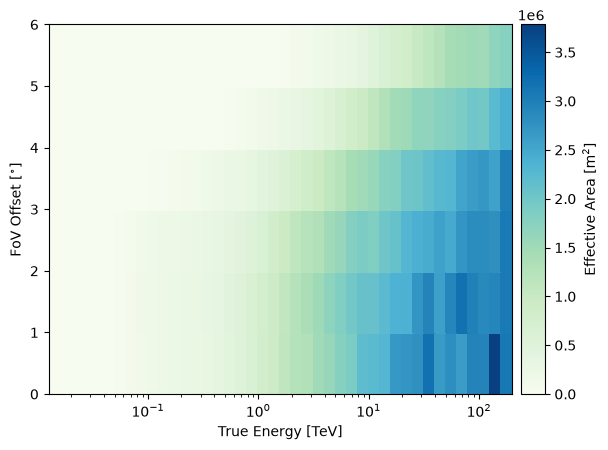

In [62]:
irfs['aeff'].plot()

#### PSF

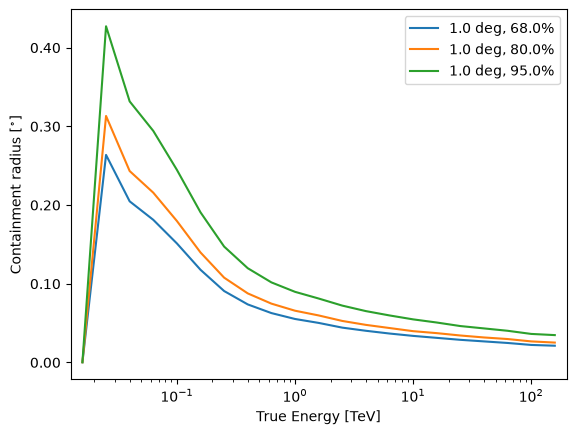

In [63]:
irfs["psf"].plot_containment_radius_vs_energy(
    offset=[1] * u.deg, fraction=[0.68, 0.8, 0.95]
)
plt.show()

#### BKG

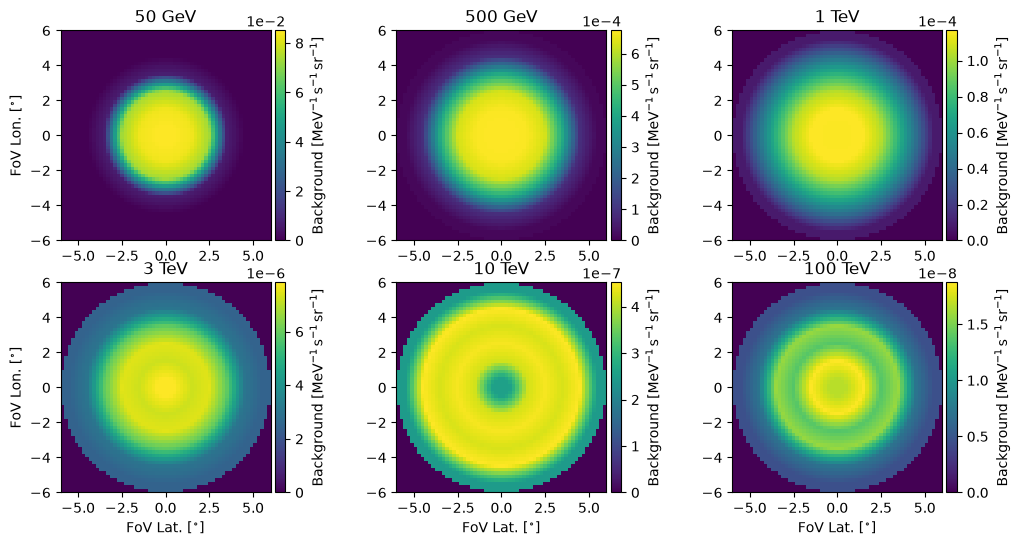

In [64]:
irfs["bkg"].plot_at_energy(
    ["50 GeV", "500 GeV", "1 TeV", "3 TeV", "10 TeV", "100 TeV"]
)
plt.show()

**Exercise**: compare IRFs of CTAO North and South sites.

*Hint: you can find the North site IRF here: $GAMMAPY_DATA/cta-caldb/Prod5-North-20deg-AverageAz-4LSTs09MSTs.180000s-v0.1.fits.gz*

In [65]:
irf_filename = (
        "$GAMMAPY_DATA/cta-caldb/Prod5-North-20deg-AverageAz-4LSTs09MSTs.180000s-v0.1.fits.gz"
)
irfs_north = load_irf_dict_from_file(irf_filename)

/Users/tbylund/miniforge3/envs/gammapy-2p1/lib/python3.13/site-packages/gammapy/irf/effective_area.py:103: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy_axis.center, area, label=label, **kwargs)


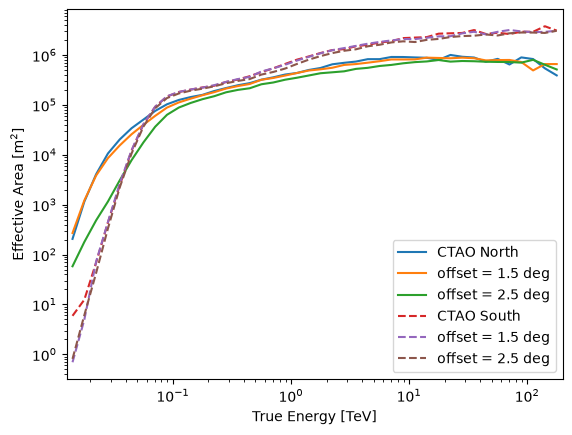

In [67]:
aeff_north = irfs_north["aeff"]
aeff_south = irfs["aeff"]

ax = aeff_north.plot_energy_dependence(offset=[0.5, 1.5, 2.5]*u.deg, label="CTAO North")
with plt.rc_context(rc={"lines.linestyle":'--'}):
    ax = aeff_south.plot_energy_dependence(offset=[0.5, 1.5, 2.5]*u.deg, label="CTAO South")
ax.set_yscale('log')
plt.legend()

**Bonus exercise**: compare Prod 5 IRFs  with the new Prod 6 IRFs. 

Gammapy packages the Prod 5 IRFs as shown above, and the new IRFs are available on [Zenodo](https://zenodo.org/records/22871179).